# Netflix Movie Recommendation System using NLP

### Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

### Load the dataset

In [3]:
df = pd.read_csv("C:/Users/HP/Downloads/netflix.csv")

# Select only the important columns
df = df.iloc[:, :5]

# Display first 5 records
df.head()

,Name,Year,Age Rating,Duration,Category
0,The Sea Beast,2022.0,7+,1h 59m,Kids & Family Movies
1,Sonic the Hedgehog,2020.0,7+,1h 41m,Kids & Family Movies
2,Tom and Jerry,2021.0,7+,1h 41m,Kids & Family Movies
3,We Can Be Heroes,2020.0,7+,1h 40m,Kids & Family Movies
4,STAND BY ME Doraemon 2,2020.0,7+,1h 37m,Kids & Family Movies


### Check the dataset

In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (2729, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2729 entries, 0 to 2728
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        2728 non-null   object 
 1   Year        2704 non-null   float64
 2   Age Rating  2704 non-null   object 
 3   Duration    2728 non-null   object 
 4   Category    2727 non-null   object 
dtypes: float64(1), object(4)
memory usage: 106.7+ KB

Missing Values:
Name           1
Year          25
Age Rating    25
Duration       1
Category       2
dtype: int64

Duplicate Records:
0


### Data Cleaning

In [5]:
# Remove rows without movie names or categories
df = df.dropna(subset=["Name", "Category"])

# Remove duplicate movie titles
df = df.drop_duplicates(subset=["Name"])

# Reset index
df = df.reset_index(drop=True)

# Fill missing values
df["Year"] = df["Year"].fillna(df["Year"].median())

df["Age Rating"] = df["Age Rating"].fillna("Not Rated")

df["Duration"] = df["Duration"].fillna("Unknown")

# Convert year into integer
df["Year"] = df["Year"].astype(int)

print("Cleaned Dataset Shape:", df.shape)

df.head()

Cleaned Dataset Shape: (1811, 5)


,Name,Year,Age Rating,Duration,Category
0,The Sea Beast,2022,7+,1h 59m,Kids & Family Movies
1,Sonic the Hedgehog,2020,7+,1h 41m,Kids & Family Movies
2,Tom and Jerry,2021,7+,1h 41m,Kids & Family Movies
3,We Can Be Heroes,2020,7+,1h 40m,Kids & Family Movies
4,STAND BY ME Doraemon 2,2020,7+,1h 37m,Kids & Family Movies


### Exploratory Data Analysis (EDA)

### **A. Top 10 movie categories**

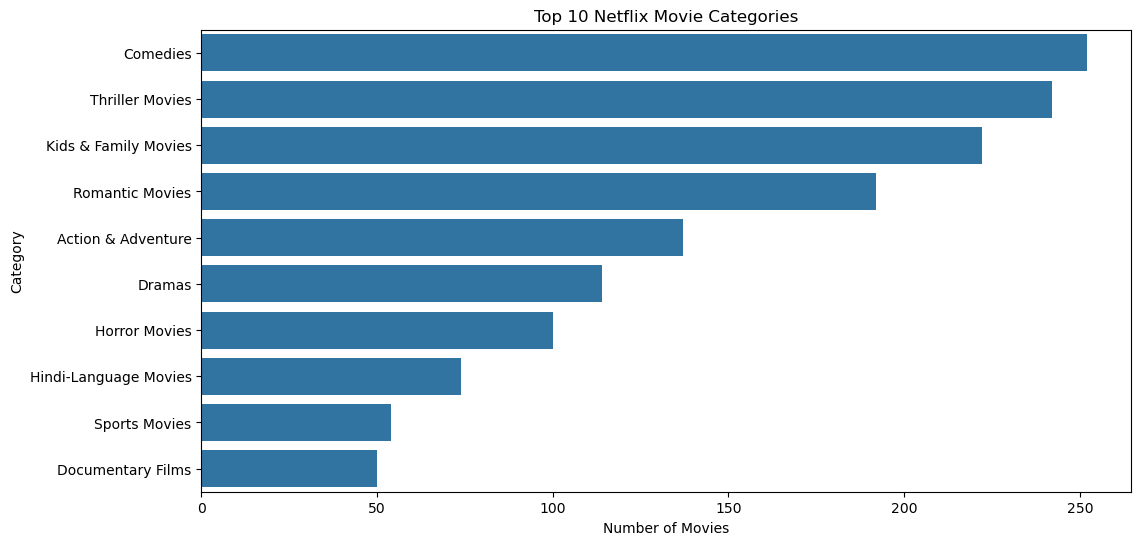

In [7]:
plt.figure(figsize=(12, 6))

top_categories = df["Category"].value_counts().head(10)

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 10 Netflix Movie Categories")
plt.xlabel("Number of Movies")
plt.ylabel("Category")

plt.show()

### **B. Movies released by year**

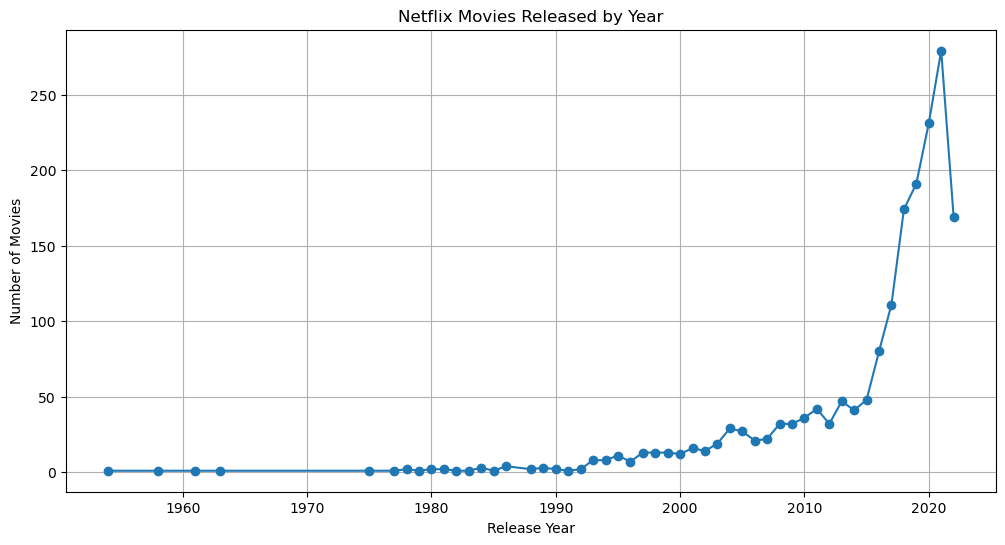

In [8]:
plt.figure(figsize=(12, 6))

year_count = df["Year"].value_counts().sort_index()

plt.plot(
    year_count.index,
    year_count.values,
    marker="o"
)

plt.title("Netflix Movies Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.grid()
plt.show()

### **C. Age rating distribution**

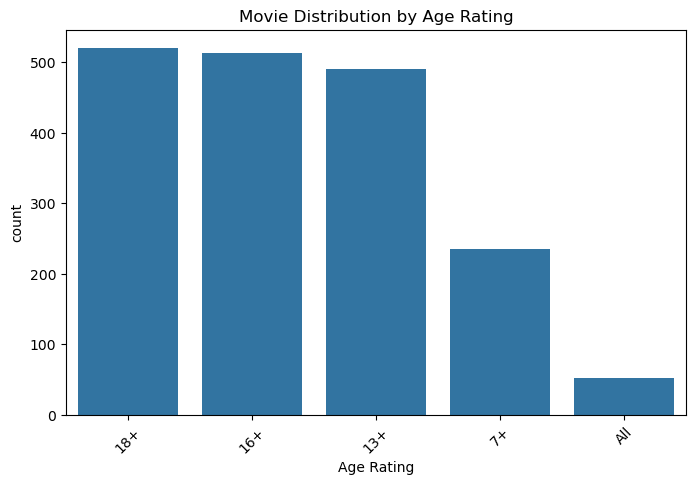

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Age Rating",
    order=df["Age Rating"].value_counts().index
)

plt.title("Movie Distribution by Age Rating")
plt.xticks(rotation=45)

plt.show()

### **D. Movie category analysis**

In [10]:
print("Total Movies:", len(df))

print("\nTop 10 Categories:")
print(df["Category"].value_counts().head(10))

print("\nAge Rating Distribution:")
print(df["Age Rating"].value_counts())

print("\nRelease Year Analysis:")
print(df["Year"].describe())

Total Movies: 1811

Top 10 Categories:
Category
Comedies                 252
Thriller Movies          242
Kids & Family Movies     222
Romantic Movies          192
Action & Adventure       137
Dramas                   114
Horror Movies            100
Hindi-Language Movies     74
Sports Movies             54
Documentary Films         50
Name: count, dtype: int64

Age Rating Distribution:
Age Rating
18+    520
16+    513
13+    490
7+     236
All     52
Name: count, dtype: int64

Release Year Analysis:
count    1811.000000
mean     2015.204859
std         8.139631
min      1954.000000
25%      2013.000000
50%      2018.000000
75%      2020.000000
max      2022.000000
Name: Year, dtype: float64


# NLP – Text preprocessing

In [11]:
# Convert text into lowercase
df["Name"] = df["Name"].str.lower()

df["Category"] = df["Category"].str.lower()

df["Age Rating"] = df["Age Rating"].str.lower()

# Create combined text features
df["Combined_Features"] = (
    df["Name"] + " " +
    df["Category"] + " " +
    df["Category"] + " " +
    df["Category"] + " " +
    df["Age Rating"]
)

# Display the result
df[["Name", "Category", "Combined_Features"]].head()

,Name,Category,Combined_Features
0,the sea beast,kids & family movies,the sea beast kids & family movies kids & fami...
1,sonic the hedgehog,kids & family movies,sonic the hedgehog kids & family movies kids &...
2,tom and jerry,kids & family movies,tom and jerry kids & family movies kids & fami...
3,we can be heroes,kids & family movies,we can be heroes kids & family movies kids & f...
4,stand by me doraemon 2,kids & family movies,stand by me doraemon 2 kids & family movies ki...


# TF-IDF Vectorization

In [12]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(
    df["Combined_Features"]
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (1811, 6063)


# Cosine Similarity

In [13]:
cosine_sim = cosine_similarity(tfidf_matrix)

print("Similarity Matrix Shape:", cosine_sim.shape)

Similarity Matrix Shape: (1811, 1811)


# Build the Movie Recommendation Function

In [15]:
from difflib import get_close_matches

def recommend_movies(movie_name, top_n=5):

    movie_name = movie_name.lower().strip()

    # Find the movie
    matches = get_close_matches(
        movie_name,
        df["Name"].tolist(),
        n=1,
        cutoff=0.6
    )

    if not matches:
        print("Movie not found. Please try another movie.")
        return

    movie_name = matches[0]

    # Get movie index
    movie_index = df[df["Name"] == movie_name].index[0]

    # Calculate similarity scores
    similarity_scores = list(
        enumerate(cosine_sim[movie_index])
    )

    # Sort movies by similarity
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Get top recommendations
    similarity_scores = similarity_scores[1:top_n + 1]

    movie_indices = [i[0] for i in similarity_scores]

    recommendations = df.iloc[movie_indices][
        ["Name", "Year", "Category", "Age Rating", "Duration"]
    ].copy()

    recommendations["Similarity Score"] = [
        round(score * 100, 2)
        for _, score in similarity_scores
    ]

    print(f"\nMovies similar to: {movie_name.title()}\n")

    return recommendations.reset_index(drop=True)

# Test the recommendation system

In [16]:
recommend_movies("The Sea Beast", top_n=10)


Movies similar to: The Sea Beast



,Name,Year,Category,Age Rating,Duration,Similarity Score
0,f.r.e.d.i.,2018,kids & family movies,7+,1h 29m,80.03
1,over the moon,2020,kids & family movies,7+,1h 40m,71.89
2,shrek,2001,kids & family movies,7+,1h 30m,71.41
3,shrek the third,2007,kids & family movies,7+,1h 34m,71.41
4,we can be heroes,2020,kids & family movies,7+,1h 40m,71.29
5,madagascar,2005,kids & family movies,7+,1h 26m,70.76
6,the witches,2020,kids & family movies,7+,1h 44m,70.47
7,only yesterday,1991,kids & family movies,7+,1h 59m,70.47
8,back to the outback,2021,kids & family movies,7+,1h 35m,70.05
9,matilda,1996,kids & family movies,7+,1h 38m,70.05


# Create an interactive Streamlit application

In [19]:
%%writefile GuptaChatbot.py
import streamlit as st
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from difflib import get_close_matches

# -----------------------------
# PAGE CONFIGURATION
# -----------------------------

st.set_page_config(
    page_title="Netflix Movie Recommender",
    page_icon="🎬",
    layout="wide"
)

# -----------------------------
# CUSTOM DESIGN
# -----------------------------

st.markdown("""
<style>
.stApp {
    background-color: #141414;
    color: white;
}

h1, h2, h3, p, label {
    color: white !important;
}

.movie-card {
    background: #252525;
    padding: 20px;
    border-radius: 12px;
    margin-bottom: 12px;
    border: 1px solid #444;
}

.stButton button {
    background-color: #E50914;
    color: white;
    border-radius: 8px;
    border: none;
}
</style>
""", unsafe_allow_html=True)

# -----------------------------
# LOAD AND PROCESS DATA
# -----------------------------

@st.cache_data
def load_data():

    data = pd.read_csv("C:/Users/HP/Downloads/netflix.csv")

    data = data.iloc[:, :5].copy()

    data = data.dropna(
        subset=["Name", "Category"]
    )

    data = data.drop_duplicates(
        subset=["Name"]
    )

    data["Year"] = pd.to_numeric(
        data["Year"], errors="coerce"
    )

    data["Year"] = data["Year"].fillna(
        data["Year"].median()
    ).astype(int)

    data["Age Rating"] = data["Age Rating"].fillna(
        "Not Rated"
    )

    data["Duration"] = data["Duration"].fillna(
        "Unknown"
    )

    data["Name"] = data["Name"].str.lower()
    data["Category"] = data["Category"].str.lower()
    data["Age Rating"] = data["Age Rating"].str.lower()

    data["Combined_Features"] = (
        data["Name"] + " " +
        data["Category"] + " " +
        data["Category"] + " " +
        data["Category"] + " " +
        data["Age Rating"]
    )

    return data.reset_index(drop=True)


df = load_data()

# -----------------------------
# NLP MODEL
# -----------------------------

@st.cache_resource
def create_model(text_data):

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    matrix = vectorizer.fit_transform(text_data)

    similarity = cosine_similarity(matrix)

    return similarity


cosine_sim = create_model(
    df["Combined_Features"]
)

# -----------------------------
# HEADER
# -----------------------------

st.title("🎬 Netflix Movie Recommender")

st.write(
    "Discover movies similar to your favourite movies "
    "using Natural Language Processing."
)

st.divider()

# -----------------------------
# SIDEBAR
# -----------------------------

st.sidebar.title("⚙️ Recommendation Settings")

top_n = st.sidebar.slider(
    "Number of Recommendations",
    min_value=5,
    max_value=10,
    value=5
)

st.sidebar.write("Powered by NLP + TF-IDF")

# -----------------------------
# MOVIE SELECTION
# -----------------------------

movie_list = sorted(df["Name"].unique())

selected_movie = st.selectbox(
    "🔍 Select your favourite movie",
    movie_list,
    index=None,
    placeholder="Search for a movie..."
)

# -----------------------------
# RECOMMENDATION FUNCTION
# -----------------------------

def recommend_movies(movie_name, top_n):

    movie_index = df[
        df["Name"] == movie_name
    ].index[0]

    scores = list(
        enumerate(cosine_sim[movie_index])
    )

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    scores = [
        item for item in scores
        if item[0] != movie_index
    ][:top_n]

    result = []

    for index, score in scores:

        movie = df.iloc[index]

        result.append({
            "Movie": movie["Name"].title(),
            "Year": movie["Year"],
            "Category": movie["Category"].title(),
            "Age Rating": movie["Age Rating"],
            "Duration": movie["Duration"],
            "Similarity": round(score * 100, 2)
        })

    return pd.DataFrame(result)


# -----------------------------
# DISPLAY RECOMMENDATIONS
# -----------------------------

if st.button("✨ Recommend Movies", use_container_width=True):

    if selected_movie:

        recommendations = recommend_movies(
            selected_movie,
            top_n
        )

        st.subheader(
            f"Movies similar to {selected_movie.title()}"
        )

        for i, row in recommendations.iterrows():

            st.markdown(
                f"""
                <div class="movie-card">
                    <h3>🎬 {i+1}. {row['Movie']}</h3>
                    <p>📅 Year: {row['Year']}</p>
                    <p>🎭 Category: {row['Category']}</p>
                    <p>🔞 Age Rating: {row['Age Rating']}</p>
                    <p>⏱️ Duration: {row['Duration']}</p>
                    <p>⭐ Similarity: {row['Similarity']}%</p>
                </div>
                """,
                unsafe_allow_html=True
            )

        st.success("Recommendations generated successfully!")

    else:

        st.warning("Please select a movie first.")

# -----------------------------
# DATASET OVERVIEW
# -----------------------------

st.divider()

st.subheader("📊 Netflix Dataset Overview")

col1, col2, col3 = st.columns(3)

with col1:
    st.metric(
        "Total Movies",
        len(df)
    )

with col2:
    st.metric(
        "Movie Categories",
        df["Category"].nunique()
    )

with col3:
    st.metric(
        "Release Years",
        df["Year"].nunique()
    )

# -----------------------------
# CATEGORY CHART
# -----------------------------

st.subheader("🎭 Top Movie Categories")

category_count = (
    df["Category"]
    .value_counts()
    .head(10)
)

st.bar_chart(category_count)

# -----------------------------
# FOOTER
# -----------------------------

st.divider()

st.caption(
    "Netflix Movie Recommendation System | "
    "Python | NLP | TF-IDF | Cosine Similarity"
)


Writing GuptaChatbot.py
